# EDA: Human vs. AI vs. Fusion text classification (EN / DE)

**UCU AI 2026 – NLP homework.** Data: processed subset of GhostWriter. Target: `human`, `ai`, `fusion` (human text partially rewritten by an LLM). Metric: macro-F1.

**Contents**
1. Setup & data loading
2. Basic data quality checks
3. Class balance (overall / language / domain) and train-vs-test composition
4. Text lengths (words, chars, XLM-R tokens)
5. Examples of each class
6. Group structure: human text and its AI / fusion versions
7. What makes fusion different? (diff against the human original, intra-text heterogeneity)
8. Stylometric features
9. Character-level and LLM-marker phrase statistics
10. Lexical differences (log-odds)
11. Train vs. test distribution shift
12. Implications for modelling

## 1. Setup & data loading

In [1]:
import os, re, glob, warnings, random, textwrap, difflib, zlib
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED); random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.width", 200)

LABELS = ["human", "ai", "fusion"]
PALETTE = {"human": "#2a9d8f", "ai": "#e76f51", "fusion": "#e9c46a"}
SAMPLE_N = 30_000      # stratified sample used for expensive per-text computations

In [2]:
def find_data_dir():
    if os.environ.get("DATA_DIR") and os.path.exists(os.path.join(os.environ["DATA_DIR"], "train.csv")):
        return os.environ["DATA_DIR"]
    # Kaggle: competition data is mounted somewhere under /kaggle/input (nesting depth differs between layouts)
    hits = glob.glob("/kaggle/input/**/train.csv", recursive=True)
    if hits:
        return os.path.dirname(sorted(hits, key=len)[0])
    for c in ["/content", "/content/drive/MyDrive", "."]:
        if os.path.exists(os.path.join(c, "train.csv")):
            return c
    raise FileNotFoundError("train.csv not found - set DATA_DIR to the folder with the competition files")

DATA_DIR = find_data_dir()
train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")
sub = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")
print("DATA_DIR:", DATA_DIR)
print("train:", train.shape, "| test:", test.shape, "| sample_submission:", sub.shape)
display(train.assign(text=train.text.str[:100] + "...").head())
train.dtypes.to_frame("dtype").T

DATA_DIR: /kaggle/input/competitions/ai-generated-text-detection-hw3-ucu-ai-2026
train: (272352, 5) | test: (25000, 4) | sample_submission: (25000, 2)


,id,text,lang,domain,label
0,e7adad,Diego's Demons Return: Is the Football Legend Losing Control? Fans have been left heartbroken and be...,en-EN,cnn_news,ai
1,3bab63,"Herr Präsident! Meine Damen und Herren! Es wird Sie nicht völlig verwundern, wenn ich nach drei Jahr...",de-DE,bundestag,human
2,4e6c1f,"Frau Präsidentin! Liebe Kolleginnen und Kollegen! Dem Kollegen Kühn stimme ich in Bezug auf das, was...",de-DE,bundestag,human
3,f92d07,[12/17/2002 9:40:16 PM | + racheal] shagging. I feel sick. I want to go throw up and throw up and th...,en-EN,blog_authorship_corpus,human
4,6162f5,"IN THE COURT OF CASE NO. , Plaintiffs, v. , Defendant. RULING ON PENSION CLAIMS I. INTRODUCTION 1. T...",en-EN,euro_court_cases,ai


,id,text,lang,domain,label
dtype,object,object,object,object,object


## 2. Basic data quality checks

In [3]:
dup_text = train[train.text.duplicated(keep=False)]
checks = {
    "train rows": len(train),
    "test rows": len(test),
    "missing values (train)": int(train.isna().sum().sum()),
    "missing values (test)": int(test.isna().sum().sum()),
    "duplicate ids (train)": int(train.id.duplicated().sum()),
    "id overlap train/test": len(set(train.id) & set(test.id)),
    "test ids == sample_submission ids": set(test.id) == set(sub.id),
    "empty / whitespace-only texts (train)": int((train.text.str.strip() == "").sum()),
    "duplicated texts (train, all copies)": len(dup_text),
    "duplicated texts with conflicting labels": int(dup_text.groupby("text").label.nunique().gt(1).sum()) if len(dup_text) else 0,
}
pd.Series(checks).to_frame("value")

,value
train rows,272352
test rows,25000
missing values (train),0
missing values (test),0
duplicate ids (train),0
id overlap train/test,0
test ids == sample_submission ids,True
empty / whitespace-only texts (train),0
"duplicated texts (train, all copies)",0
duplicated texts with conflicting labels,0


In [4]:
print("Unique values:")
print("  lang  :", sorted(train.lang.unique()))
print("  domain:", sorted(train.domain.unique()))
print("  label :", sorted(train.label.unique()))
pd.crosstab(train.domain, train.lang, margins=True)

Unique values:
  lang  : ['de-DE', 'en-EN']
  domain: ['arxiv_papers', 'blog_authorship_corpus', 'bundestag', 'cnn_news', 'euro_court_cases', 'gutenberg', 'house_of_commons', 'student_essays']
  label : ['ai', 'fusion', 'human']


lang,de-DE,en-EN,All
domain,,,
arxiv_papers,0,14290,14290
blog_authorship_corpus,0,40547,40547
bundestag,52343,0,52343
cnn_news,0,44285,44285
euro_court_cases,0,27578,27578
gutenberg,428,6916,7344
house_of_commons,0,31859,31859
student_essays,0,54106,54106
All,52771,219581,272352


## 3. Class balance

,count,share
label,,
human,66730,0.245
ai,121940,0.448
fusion,83682,0.307


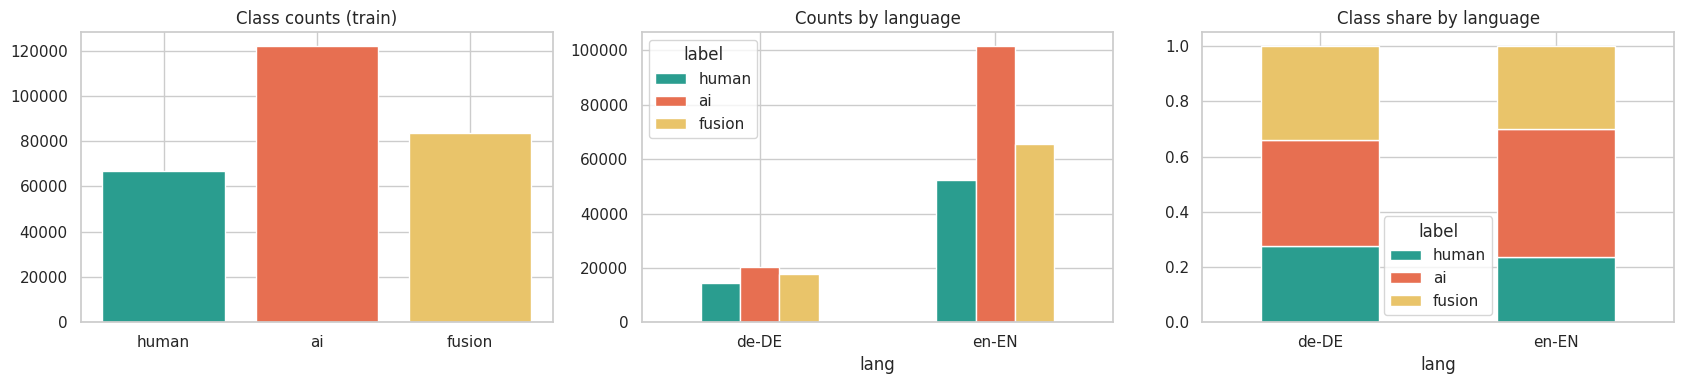

label,human,ai,fusion,total
lang,,,,
de-DE,14510,20337,17924,52771
en-EN,52220,101603,65758,219581


label,human,ai,fusion
lang,,,
de-DE,0.275,0.385,0.340
en-EN,0.238,0.463,0.299


In [5]:
overall = train.label.value_counts().reindex(LABELS)
display(pd.DataFrame({"count": overall, "share": overall / overall.sum()}))

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].bar(LABELS, overall.values, color=[PALETTE[l] for l in LABELS]); axes[0].set_title("Class counts (train)")

ct_lang = pd.crosstab(train.lang, train.label)[LABELS]
ct_lang.plot(kind="bar", ax=axes[1], color=[PALETTE[l] for l in LABELS], rot=0); axes[1].set_title("Counts by language")

sh_lang = ct_lang.div(ct_lang.sum(1), axis=0)
sh_lang.plot(kind="bar", stacked=True, ax=axes[2], color=[PALETTE[l] for l in LABELS], rot=0); axes[2].set_title("Class share by language")
plt.tight_layout(); plt.show()
display(ct_lang.assign(total=ct_lang.sum(1)))
display(sh_lang)

label                         human     ai  fusion  total
lang  domain                                             
de-DE bundestag               14479  19977   17887  52343
      gutenberg                  31    360      37    428
en-EN arxiv_papers              407  12050    1833  14290
      blog_authorship_corpus  12466  15684   12397  40547
      cnn_news                13395  19488   11402  44285
      euro_court_cases         6277  11141   10160  27578
      gutenberg                 216   6359     341   6916
      house_of_commons         6953  15298    9608  31859
      student_essays          12506  21583   20017  54106

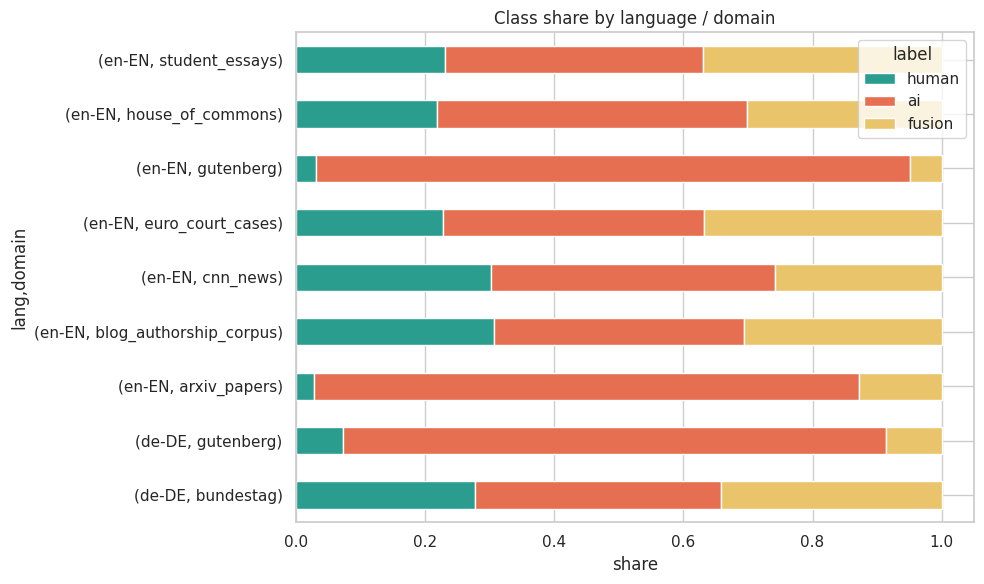

In [6]:
ct_dom = pd.crosstab([train.lang, train.domain], train.label)[LABELS]
sh_dom = ct_dom.div(ct_dom.sum(1), axis=0)
display(ct_dom.assign(total=ct_dom.sum(1)))

ax = sh_dom.plot(kind="barh", stacked=True, figsize=(10, 6), color=[PALETTE[l] for l in LABELS])
ax.set_title("Class share by language / domain"); ax.set_xlabel("share"); plt.tight_layout(); plt.show()

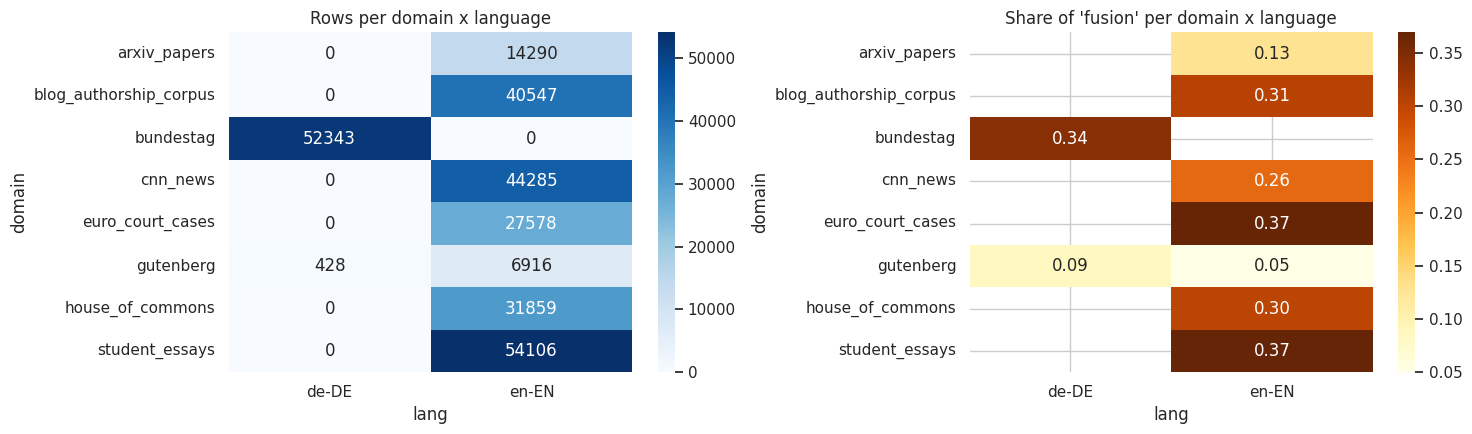

In [7]:
# language x domain size heatmap + fusion share heatmap
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.heatmap(pd.crosstab(train.domain, train.lang), annot=True, fmt="d", cmap="Blues", ax=axes[0]); axes[0].set_title("Rows per domain x language")
fusion_share = train.assign(is_f=(train.label == "fusion")).pivot_table(index="domain", columns="lang", values="is_f", aggfunc="mean")
sns.heatmap(fusion_share, annot=True, fmt=".2f", cmap="YlOrBr", ax=axes[1]); axes[1].set_title("Share of 'fusion' per domain x language")
plt.tight_layout(); plt.show()

- The training dataset is moderately imbalanced: **AI accounts for 44.8%**, fusion for 30.7%, and human for 24.5%. Therefore, macro-F1 is more appropriate than accuracy because it gives equal importance to all three classes.
- English texts dominate the dataset (80.6%), while German texts represent 19.4%.
- Class distributions vary across languages and domains. For example, AI-generated texts are particularly common in arXiv papers and Gutenberg books. This creates a risk that models will learn domain-specific patterns instead of authorship characteristics.

### 3.1 Train vs. test composition (language / domain)

In [8]:
for col in ["lang", "domain"]:
    comp = pd.concat([train[col].value_counts(normalize=True).rename("train"),
                      test[col].value_counts(normalize=True).rename("test")], axis=1)
    comp["diff"] = comp["test"] - comp["train"]
    display(comp)

,train,test,diff
lang,,,
en-EN,0.806,0.853,0.046
de-DE,0.194,0.147,-0.046


,train,test,diff
domain,,,
student_essays,0.199,0.159,-0.040
bundestag,0.192,0.143,-0.049
cnn_news,0.163,0.197,0.035
blog_authorship_corpus,0.149,0.178,0.029
house_of_commons,0.117,0.118,0.001
euro_court_cases,0.101,0.064,-0.038
arxiv_papers,0.052,0.067,0.015
gutenberg,0.027,0.074,0.047


- Train and test distributions are not identical. The proportion of English texts increases from **80.6% in training to 85.3% in test**, while the proportion of German texts decreases.
- Domain distributions also change. For example, Gutenberg increases from 2.7% to 7.4%, while Bundestag decreases from 19.2% to 14.3%.
- These differences indicate a potential distribution shift that may affect generalization. Since test labels are unavailable, no conclusions can be made about the test class distribution.

## 4. Text lengths

In [9]:
for df in (train, test):
    df["n_words"] = df.text.str.split().str.len()
    df["n_chars"] = df.text.str.len()

# stratified sample used for the expensive computations below (fixed for the whole notebook)
frac = min(1.0, SAMPLE_N / len(train))
train_s = (train.groupby(["label", "lang", "domain"], group_keys=False)
                .sample(frac=frac, random_state=SEED).reset_index(drop=True))
print("sample size:", len(train_s))

display(train.n_words.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).to_frame("n_words (train)").join(
        test.n_words.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).to_frame("n_words (test)")))

sample size: 29999


,n_words (train),n_words (test)
count,272352.000,25000.000
mean,542.336,518.470
std,426.749,406.631
min,20.000,20.000
1%,29.000,24.000
5%,65.000,50.000
25%,273.000,239.000
50%,463.000,458.000
75%,686.000,683.000
95%,1263.000,1177.050


In [10]:
pct = [.05, .25, .5, .75, .95]
display(train.groupby("label").n_words.describe(percentiles=pct).reindex(LABELS))
display(train.groupby(["lang", "label"]).n_words.describe(percentiles=pct).reindex(LABELS, level=1))

,count,mean,std,min,5%,25%,50%,75%,95%,max
label,,,,,,,,,,
human,66730.000,577.926,473.393,20.000,57.000,262.000,481.000,740.000,1490.000,2998.000
ai,121940.000,493.478,294.318,20.000,60.000,287.000,465.000,657.000,1008.000,2996.000
fusion,83682.000,585.152,530.534,20.000,79.000,263.000,445.000,695.000,1820.000,3000.000


count    mean     std    min      5%     25%     50%     75%      95%      max
lang  label                                                                                     
de-DE human   14510.000 590.184 304.511 20.000  93.000 428.000 584.000 745.000 1074.550 2963.000
      ai      20337.000 424.665 183.399 20.000  84.000 339.000 430.000 533.000  710.000 2679.000
      fusion  17924.000 615.331 261.397 23.000 255.150 455.000 584.000 736.000 1048.000 2952.000
en-EN human   52220.000 574.520 510.445 20.000  51.000 239.000 439.000 737.000 1618.050 2998.000
      ai     101603.000 507.252 309.987 20.000  56.000 276.000 481.000 691.000 1040.000 2996.000
      fusion  65758.000 576.925 582.450 20.000  68.000 228.000 389.000 663.000 2032.150 3000.000

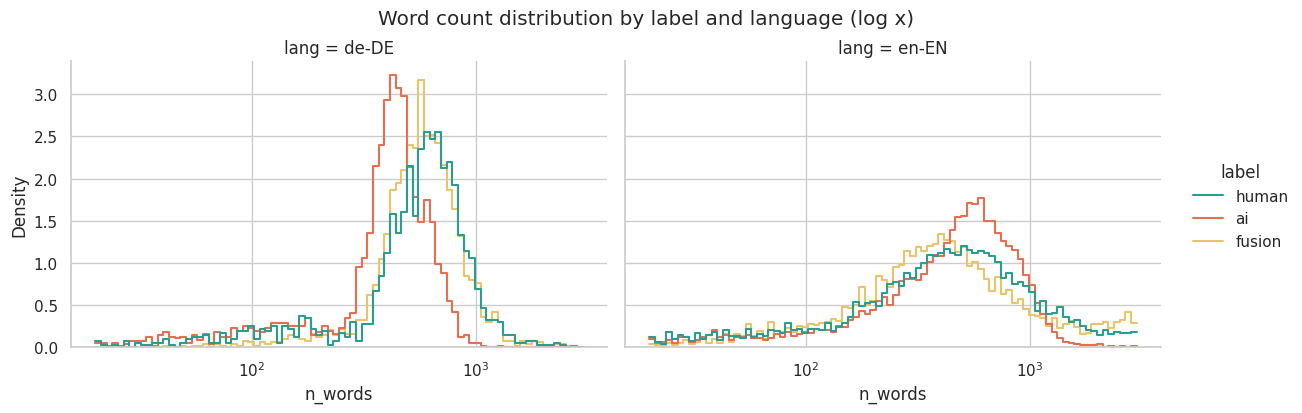

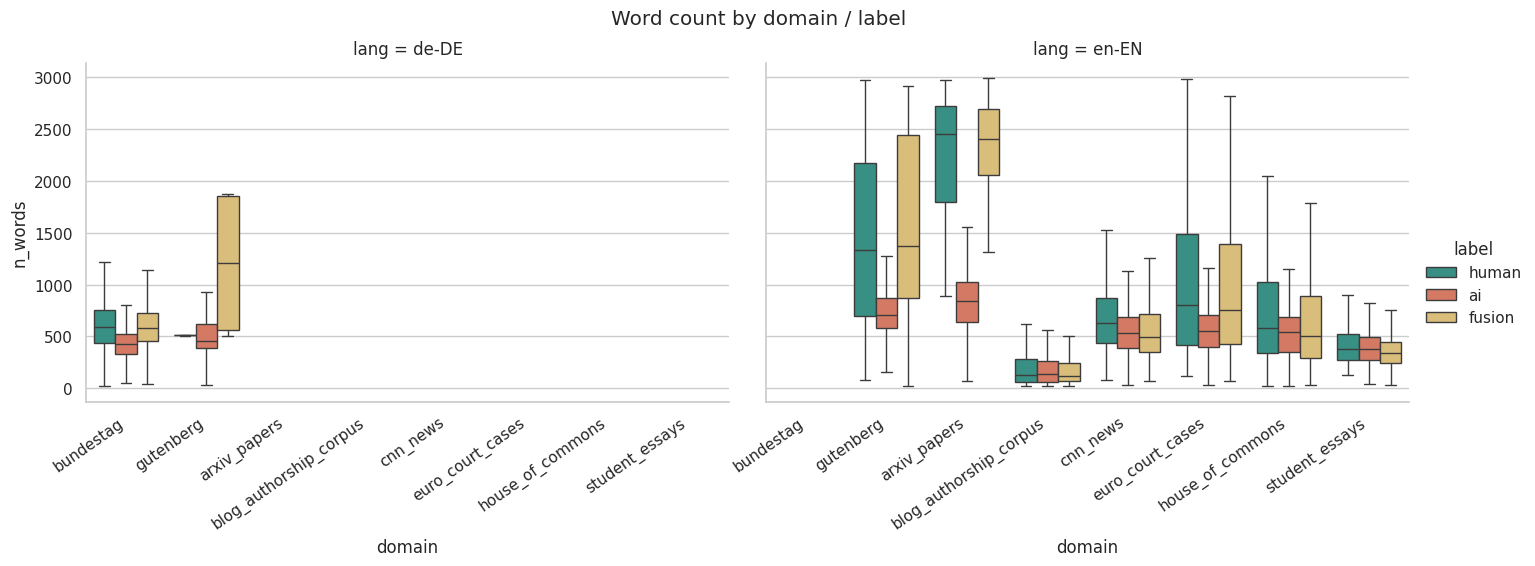

In [11]:
g = sns.displot(train_s, x="n_words", hue="label", hue_order=LABELS, palette=PALETTE, col="lang",
                log_scale=True, element="step", stat="density", common_norm=False, fill=False,
                height=4, aspect=1.5)
g.fig.suptitle("Word count distribution by label and language (log x)", y=1.03); plt.show()

g = sns.catplot(data=train_s, x="domain", y="n_words", hue="label", hue_order=LABELS, palette=PALETTE,
                col="lang", kind="box", showfliers=False, height=4.5, aspect=1.6)
g.set_xticklabels(rotation=35, ha="right"); g.fig.suptitle("Word count by domain / label", y=1.03); plt.show()

In [12]:
med = train.pivot_table(index=["lang", "domain"], columns="label", values="n_words", aggfunc="median")[LABELS]
med["ai/human"] = med["ai"] / med["human"]
med["fusion/human"] = med["fusion"] / med["human"]
display(med)

label                           human      ai   fusion  ai/human  fusion/human
lang  domain                                                                  
de-DE bundestag               585.000 429.000  584.000     0.733         0.998
      gutenberg               517.000 465.500  531.000     0.900         1.027
en-EN arxiv_papers           2382.000 824.000 2344.000     0.346         0.984
      blog_authorship_corpus  137.000 129.000  128.000     0.942         0.934
      cnn_news                627.000 530.000  501.000     0.845         0.799
      euro_court_cases        854.000 550.000  764.000     0.644         0.895
      gutenberg              1237.000 707.000 1586.000     0.572         1.282
      house_of_commons        554.000 547.000  509.000     0.987         0.919
      student_essays          388.000 371.000  343.000     0.956         0.884

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

,count,mean,std,min,25%,50%,75%,max
lang,,,,,,,,
de-DE,947.000,1.521,0.077,1.271,1.465,1.514,1.566,1.912
en-EN,4053.000,1.437,0.150,1.078,1.343,1.420,1.508,2.607


label,human,ai,fusion,all
>128 tokens,0.897,0.926,0.939,0.923
>256 tokens,0.803,0.853,0.848,0.840
>512 tokens,0.605,0.670,0.607,0.635
>1024 tokens,0.259,0.236,0.244,0.244
>2048 tokens,0.045,0.010,0.077,0.039


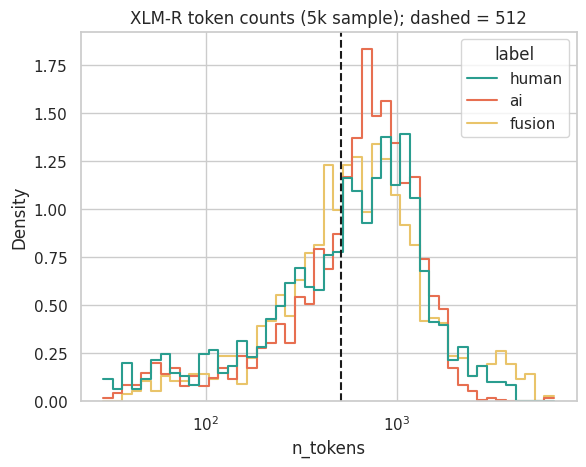

In [13]:
# Length in XLM-R tokens (relevant for the 512-token limit of encoders)
# Count tokens in small batches; don't truncate, since we want to measure the full length.
try:
    from transformers import AutoTokenizer
    tok = AutoTokenizer.from_pretrained("xlm-roberta-base")
    tk = train_s.sample(min(5000, len(train_s)), random_state=SEED).copy()
    lengths = []
    batch_size = 32
    for start in range(0, len(tk), batch_size):
        batch = tk.text.iloc[start:start + batch_size].tolist()
        encoded = tok(batch, add_special_tokens=True, truncation=False, verbose=False)
        lengths.extend(map(len, encoded["input_ids"]))
    tk["n_tokens"] = lengths
    tk["tok_per_word"] = tk.n_tokens / tk.n_words.clip(lower=1)
    display(tk.groupby("lang").tok_per_word.describe())
    rows = []
    for thr in (128, 256, 512, 1024, 2048):
        r = tk.groupby("label").n_tokens.apply(lambda s: (s > thr).mean()).reindex(LABELS)
        r["all"] = (tk.n_tokens > thr).mean()
        r.name = f">{thr} tokens"
        rows.append(r)
    display(pd.DataFrame(rows))
    sns.histplot(data=tk, x="n_tokens", hue="label", hue_order=LABELS, palette=PALETTE,
                 log_scale=True, element="step", fill=False, stat="density", common_norm=False)
    plt.axvline(512, color="k", ls="--")
    plt.title("XLM-R token counts (5k sample); dashed = 512")
    plt.show()
except Exception as e:
    print("Tokenizer check skipped:", repr(e)[:200])

- Document lengths vary considerably, from 20 to 3,000 words. The median length is **463 words in training** and 458 words in test.
- AI-generated texts are shorter on average (493 words) than human (578) and fusion texts (585). However, these differences also depend on domain, so length alone is not a reliable indicator of authorship.
- Approximately **63.5% of sampled texts exceed the 512-token limit of XLM-RoBERTa**. This motivates using head-and-tail truncation or other strategies for handling long documents.

## 5. Examples of each class

In [14]:
def show(label, lang, n=1, chars=600, seed=SEED):
    rows = train[(train.label == label) & (train.lang == lang)].sample(n, random_state=seed)
    for _, r in rows.iterrows():
        print(f"[{label.upper()} | {r.lang} | {r.domain} | {r.n_words} words | id={r.id}]")
        print(textwrap.fill(r.text[:chars].replace("\n", " <NL> "), 130)); print()

for lang in sorted(train.lang.unique()):
    for label in LABELS:
        show(label, lang)

[HUMAN | de-DE | bundestag | 79 words | id=d57723]
Wir haben es dank der Unterstützung des Gesetzgebers möglich gemacht, dass Rehabilitationseinrichtungen, die ja im Moment auch
weniger genutzt werden, für die Kurzzeitpflege genutzt werden können. Ich bin gerade mit den Ländern im Gespräch, wie wir
regelhafter, noch bevor jemand aus dem Krankenhaus in eine stationäre Pflegeeinrichtung zurückkehrt, eine Art Kurzzeitpflege
während der Quarantäne etwa in einer Rehaeinrichtung möglich machen, um das Risiko, dass etwa infolge einer Verlegung eine
Infektion in die Pflegeeinrichtung getragen wird, möglichst weit zu minimieren.

[AI | de-DE | bundestag | 277 words | id=3c9308]
"Sehr geehrte Damen und Herren, liebe Kolleginnen und Kollegen, heute möchte ich mich zum Gesetzentwurf zur Vereinfachung des
Meldewesens im Gastgewerbe äußern. Wie wir alle wissen, ist unsere deutsche Gastronomie ein essenzieller Teil unserer Wirtschaft
und eines unverzichtbaren Aushängeschilds unseres Landes. Es leiste

- The examples demonstrate substantial variation in writing styles across languages and domains, including parliamentary speeches, court judgments, and other genres.
- Some AI-generated texts contain more standardized introductions, while human and fusion texts may preserve domain-specific formatting and expressions.
- However, these observations are qualitative and cannot be treated as universal classification rules.

## 6. Group structure: a human text and its AI / fusion versions

The dataset description says that variants derived from the same source text are kept on the same side of the train/test split. Consequently, random row-wise validation may still mix related examples.

We recover **approximate** groups with a two-stage similarity check:

1. Generate candidate matches from compact MinHash-style keys over word 5-grams (not from a single collision alone).
2. Verify candidates by Jaccard similarity of 5-gram sets and require the **same language and domain**. Very frequent keys are ignored because they are dominated by boilerplate and create spurious links.

The procedure is conservative and cannot reproduce the dataset's true source-document IDs. In particular, strongly rewritten AI/fusion variants may fail to match, and some highly formulaic texts could still be mistaken for related documents. **Recovered groups must not be interpreted as ground truth.**


In [15]:
# More conservative approximation: candidate generation + content verification.
# A single MinHash-key collision is never sufficient to create a group.
from collections import defaultdict

SEEDS = (0x9E3779B1, 0x85EBCA6B, 0xC2B2AE35)
NGRAM = 5
MIN_JACCARD = 0.60
MAX_BUCKET = 40       # discard extremely common boilerplate keys


def shingles(text, ngram=NGRAM, n_words=180):
    words = re.findall(r"\w+", str(text).lower())[:n_words]
    if len(words) < ngram:
        return {zlib.crc32(" ".join(words).encode("utf-8"))} if words else set()
    return {zlib.crc32(" ".join(words[i:i + ngram]).encode("utf-8"))
            for i in range(len(words) - ngram + 1)}


def sketch_from_shingles(hs):
    if not hs:
        return tuple([-1] * len(SEEDS))
    h = np.fromiter(hs, dtype=np.uint64)
    return tuple(int(np.min(h ^ np.uint64(seed))) for seed in SEEDS)


def jaccard(a, b):
    if not a or not b:
        return 0.0
    intersection = len(a & b)
    return intersection / (len(a) + len(b) - intersection)


def build_sketches(texts):
    # Keep full shingles only for verification; 5-gram hashes are compact.
    sets = [shingles(t) for t in texts]
    keys = [sketch_from_shingles(s) for s in sets]
    return sets, keys


def candidate_index(keys, metadata):
    index = defaultdict(list)
    for i, (key, meta) in enumerate(zip(keys, metadata)):
        for k, val in enumerate(key):
            if val != -1:
                index[(meta[0], meta[1], k, val)].append(i)
    # Drop high-frequency keys that tend to represent generic boilerplate.
    return {key: ids for key, ids in index.items() if len(ids) <= MAX_BUCKET}


def matching_candidates(key, meta, index, min_keys=2):
    counts = Counter()
    for k, val in enumerate(key):
        if val != -1:
            counts.update(index.get((meta[0], meta[1], k, val), ()))
    return [i for i, count in counts.items() if count >= min_keys]


train_meta = list(zip(train.lang, train.domain))
train_shingles, train_sk = build_sketches(train.text.tolist())
train_index = candidate_index(train_sk, train_meta)
parent = list(range(len(train)))


def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x


checked_pairs = set()
verified_links = 0
for i, (key, meta) in enumerate(zip(train_sk, train_meta)):
    for j in matching_candidates(key, meta, train_index):
        if j >= i:
            continue
        pair = (j, i)
        if pair in checked_pairs:
            continue
        checked_pairs.add(pair)
        if jaccard(train_shingles[i], train_shingles[j]) >= MIN_JACCARD:
            ra, rb = find(i), find(j)
            if ra != rb:
                parent[ra] = rb
                verified_links += 1

train["group"] = [find(i) for i in range(len(train))]
grp_size = train.groupby("group").size()
print("n groups:", grp_size.shape[0], "| rows:", len(train), "| verified links:", verified_links)
display(grp_size.value_counts().sort_index().head(15).to_frame("n_groups").rename_axis("group size"))


n groups: 224567 | rows: 272352 | verified links: 47785


,n_groups
group size,
1,190479
2,22286
3,10670
4,759
5,149
6,158
7,41
8,13
9,1


In [16]:
comp = train.groupby("group").label.agg(lambda s: "+".join(sorted(s)))
display(comp.value_counts().head(12).to_frame("n_groups"))

# Unlike a raw shared-sketch-key rate, these candidates are checked for actual
# content similarity. Still not a definitive leakage test or proof of shared sources.
test_meta = list(zip(test.lang, test.domain))
test_shingles, test_sk = build_sketches(test.text.tolist())
verified_test_matches = 0
for sh, key, meta in zip(test_shingles, test_sk, test_meta):
    candidates = matching_candidates(key, meta, train_index)
    if any(jaccard(sh, train_shingles[i]) >= MIN_JACCARD for i in candidates):
        verified_test_matches += 1

print(f"test rows with a verified approximate 5-gram match to train: "
      f"{verified_test_matches}/{len(test)} ({verified_test_matches/len(test):.2%})")
print("This is an approximate similarity diagnostic, NOT an estimate of source-group leakage.")
# Free the large temporary shingle tables after verification: subsequent sections
# use only group ids and original texts.
del train_shingles, test_shingles, train_index, checked_pairs


,n_groups
label,
ai,121866
fusion,34785
human,33828
fusion+human,20658
fusion+fusion+human,10546
fusion+fusion,1540
fusion+fusion+fusion+human,641
fusion+fusion+fusion+fusion+fusion+human,116
fusion+fusion+human+human,107


test rows with a verified approximate 5-gram match to train: 9/25000 (0.04%)
This is an approximate similarity diagnostic, NOT an estimate of source-group leakage.


label,ai/human,fusion/human
count,2.000,32382.000
mean,0.934,0.878
std,0.060,0.148
min,0.892,0.160
5%,0.896,0.590
25%,0.913,0.794
50%,0.934,0.913
75%,0.956,0.989
95%,0.973,1.042
max,0.977,3.204


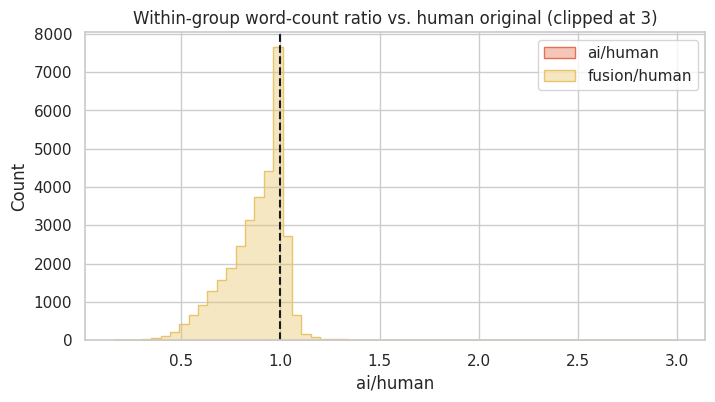

In [17]:
# Within-group length ratios (only groups that contain the needed classes)
piv = train.groupby(["group", "label"]).n_words.median().unstack()
for a in ("ai", "fusion"):
    piv[f"{a}/human"] = piv[a] / piv["human"]
display(piv[["ai/human", "fusion/human"]].describe(percentiles=[.05, .25, .5, .75, .95]))
fig, ax = plt.subplots(figsize=(8, 4))
for c, col in (("ai/human", PALETTE["ai"]), ("fusion/human", PALETTE["fusion"])):
    sns.histplot(piv[c].dropna().clip(0, 3), bins=60, color=col, label=c, element="step", alpha=.4, ax=ax)
ax.axvline(1, color="k", ls="--"); ax.set_title("Within-group word-count ratio vs. human original (clipped at 3)"); ax.legend(); plt.show()

- Approximate text similarity analysis identified **224,567 candidate groups** among 272,352 training examples. Some groups contain related human and fusion texts.
- Within matched human–fusion groups, the median fusion-to-human length ratio is approximately **0.913**, indicating that fusion versions are often slightly shorter.
- Only 9 of 25,000 test documents had a verified approximate 5-gram match to training texts under this method. However, this does not guarantee the absence of related documents across datasets.
- Related text variants may also occur on both sides of a random training/validation split, potentially making validation results optimistic. Group-disjoint validation would be preferable if reliable source identifiers were available.

## 7. What makes fusion different?

### 7.1 Word-level diff between a fusion text and its human original
For groups containing both a `human` and a `fusion` (or `ai`) text we align the texts with `difflib` and measure
(a) which fraction of the rewritten text is *not* present in the original, (b) where along the text the changes are, (c) how contiguous the changed region is.

label                              ai  fusion
frac_changed              count 2.000  60.000
                          mean  0.048   0.175
                          std   0.067   0.137
                          min   0.000   0.003
                          25%   0.024   0.073
                          50%   0.048   0.152
                          75%   0.071   0.240
                          max   0.095   0.535
longest_changed_run_share count 2.000  60.000
                          mean  0.250   0.595
                          std   0.354   0.271
                          min   0.000   0.167
                          25%   0.125   0.374
                          50%   0.250   0.594
                          75%   0.375   0.852
                          max   0.500   1.000

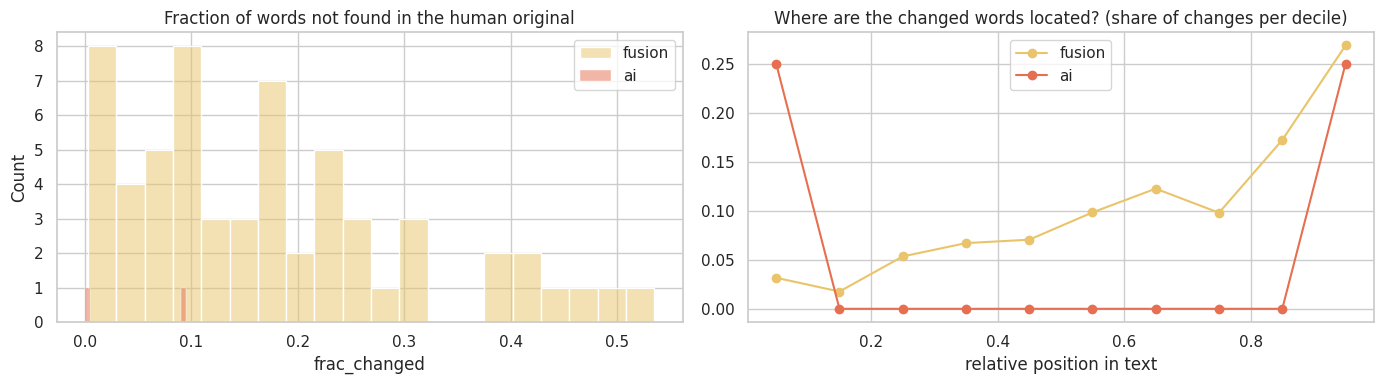

In [18]:
def change_mask(h_text, x_text):
    h, x = h_text.split(), x_text.split()
    sm = difflib.SequenceMatcher(None, h, x, autojunk=False)
    changed = np.ones(len(x), bool)
    for a, b, size in sm.get_matching_blocks():
        changed[b:b + size] = False
    return changed

def longest_run(mask):
    best = cur = 0
    for v in mask:
        cur = cur + 1 if v else 0; best = max(best, cur)
    return best

rng = np.random.RandomState(SEED)
n_pairs = 60
labs = train.groupby("group").label.agg(set)
res = []
for other in ("fusion", "ai"):
    gids = labs[labs.apply(lambda s: {"human", other} <= s)].index.values.copy()
    rng.shuffle(gids)
    done = 0
    for gid in gids:
        sub_g = train[train.group == gid]
        h = sub_g[sub_g.label == "human"].iloc[0]; x = sub_g[sub_g.label == other].iloc[0]
        if h.n_words > 1000 or x.n_words > 1000: continue
        m = change_mask(h.text, x.text)
        if len(m) == 0: continue
        pos = np.histogram(np.where(m)[0] / len(m), bins=10, range=(0, 1))[0] / max(m.sum(), 1)
        res.append({"label": other, "domain": x.domain, "frac_changed": m.mean(),
                    "longest_changed_run_share": longest_run(m) / max(m.sum(), 1), "pos": pos})
        done += 1
        if done >= n_pairs: break
diff_df = pd.DataFrame(res)
if len(diff_df):
    display(diff_df.groupby("label")[["frac_changed", "longest_changed_run_share"]].describe().T)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    for lab in ("fusion", "ai"):
        d = diff_df[diff_df.label == lab]
        if len(d):
            sns.histplot(d.frac_changed, bins=20, ax=axes[0], color=PALETTE[lab], label=lab, alpha=.5)
            axes[1].plot(np.linspace(0.05, 0.95, 10), np.mean(np.vstack(d.pos), 0), marker="o", color=PALETTE[lab], label=lab)
    axes[0].set_title("Fraction of words not found in the human original"); axes[0].legend()
    axes[1].set_title("Where are the changed words located? (share of changes per decile)"); axes[1].set_xlabel("relative position in text"); axes[1].legend()
    plt.tight_layout(); plt.show()
else:
    print("No human/fusion/ai groups recovered - check the grouping step.")

In [19]:
# Side-by-side example of one group (human / fusion / ai), first 500 characters of each
cand = labs[labs.apply(lambda s: {"human", "fusion", "ai"} <= s)].index
if len(cand):
    gid = np.random.RandomState(1).choice(cand)
    for lab in LABELS:
        r = train[(train.group == gid) & (train.label == lab)].iloc[0]
        print(f"[{lab.upper()} | {r.lang} | {r.domain} | {r.n_words} words]")
        print(textwrap.fill(r.text[:500].replace("\n", " <NL> "), 130)); print()
else:
    print("No complete human+fusion+ai group found.")

No complete human+fusion+ai group found.


- In the sample of 60 matched fusion texts, the median proportion of words not aligned with the human original is approximately **15.2%**.
- Changes are often concentrated in specific passages rather than distributed uniformly throughout the document.
- This suggests that fusion texts can preserve much of the original human writing, making them difficult to detect using global document-level features.
- These findings are exploratory because they rely on a relatively small sample of approximately matched texts.

### 7.2 Intra-text heterogeneity
Hypothesis: a fusion text mixes human and LLM passages, so style statistics should vary **more between segments of the same text** than in a purely human or purely AI text.
We cut each text into 4 equal segments and compute the coefficient of variation (std / mean) of the segment statistics.

cv_sent_len  cv_word_len  cv_ttr  cv_comma_rate
lang  label                                                  
de-DE human         0.178        0.044   0.041          0.248
      ai            0.154        0.044   0.041          0.222
      fusion        0.166        0.048   0.046          0.235
en-EN human         0.203        0.045   0.055          0.443
      ai            0.160        0.045   0.045          0.303
      fusion        0.208        0.074   0.070          0.463

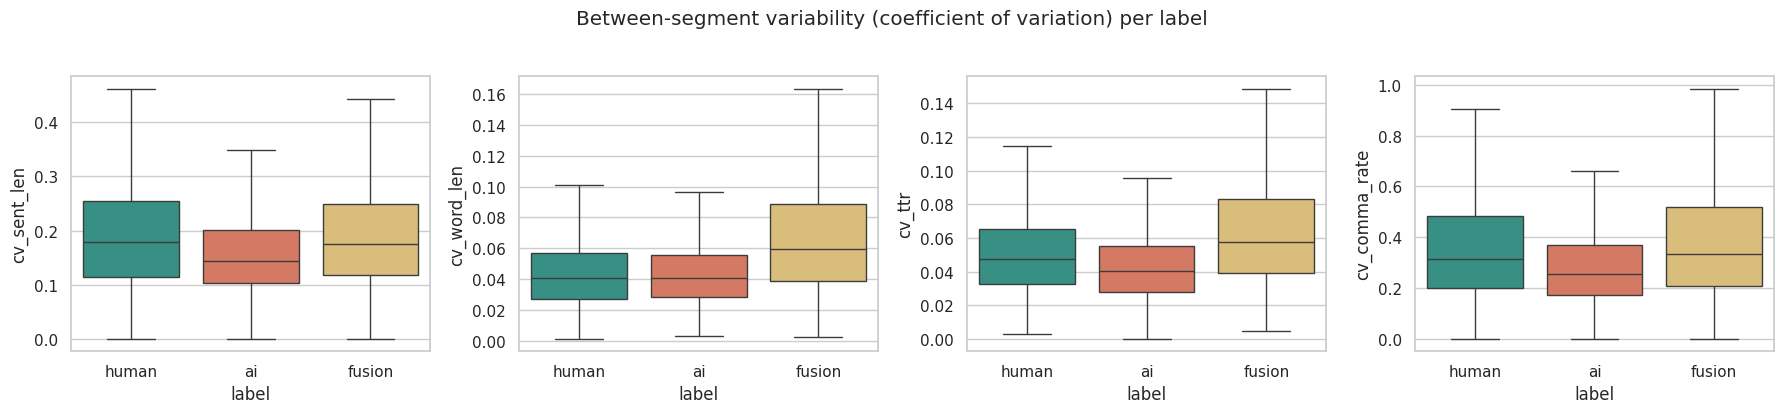

In [20]:
def segment_cv(text, k=4):
    words = text.split(); n = len(words)
    if n < k * 25: return None
    out = []
    for i in range(k):
        seg = " ".join(words[i * n // k:(i + 1) * n // k])
        sents = [s for s in re.split(r"(?<=[.!?])\s+", seg) if s.strip()]
        sl = [len(s.split()) for s in sents] or [0]
        ws = re.findall(r"\w+", seg.lower()) or ["_"]
        out.append((np.mean(sl), np.mean([len(x) for x in ws]), len(set(ws)) / len(ws), seg.count(",") / len(ws)))
    a = np.array(out)
    return a.std(0) / (a.mean(0) + 1e-9)

hs = train_s.sample(min(10_000, len(train_s)), random_state=SEED)
cvs = [segment_cv(t) for t in hs.text]
ok = [c is not None for c in cvs]
H = pd.DataFrame([c for c in cvs if c is not None], columns=["cv_sent_len", "cv_word_len", "cv_ttr", "cv_comma_rate"])
H["label"] = hs.label.values[ok]; H["lang"] = hs.lang.values[ok]
display(H.groupby(["lang", "label"]).mean().reindex(LABELS, level=1))
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, H.columns[:4]):
    sns.boxplot(data=H, x="label", y=c, order=LABELS, palette=PALETTE, showfliers=False, ax=ax)
plt.suptitle("Between-segment variability (coefficient of variation) per label", y=1.03); plt.tight_layout(); plt.show()

- English fusion texts show greater variation between segments in average word length and lexical diversity than either human or AI texts in the analyzed sample.
- For example, the coefficient of variation in word length is **0.074 for fusion**, compared with 0.045 for both human and AI texts.
- This supports the hypothesis that fusion documents may contain local stylistic inconsistencies caused by mixing human-written and AI-generated passages.
- However, the pattern is language-dependent and is less consistent in German texts.

## 8. Stylometric features

In [21]:
def style_features(text):
    words = re.findall(r"\w+", text); nw = max(len(words), 1)
    low = [w.lower() for w in words]; first = low[:300]
    sents = [s for s in re.split(r"(?<=[.!?])\s+", text) if s.strip()]
    sl = np.array([len(s.split()) for s in sents]) if sents else np.array([0])
    wl = np.array([len(w) for w in words]) if words else np.array([0])
    return {
        "avg_word_len": wl.mean(),
        "long_word_ratio": (wl >= 10).mean(),
        "ttr_300": len(set(first)) / max(len(first), 1),
        "avg_sent_len": sl.mean(), "std_sent_len": sl.std(),
        "cv_sent_len": sl.std() / (sl.mean() + 1e-9), "max_sent_len": sl.max(),
        "comma_per_word": text.count(",") / nw,
    }

S = pd.DataFrame([style_features(t) for t in train_s.text])
nc = train_s.n_chars.clip(lower=1)
S["punct_ratio"] = train_s.text.str.count(r"[^\w\s]") / nc
S["digit_ratio"] = train_s.text.str.count(r"\d") / nc
S["upper_ratio"] = train_s.text.str.count(r"[A-ZÄÖÜ]") / nc
S["non_ascii_ratio"] = train_s.text.str.count(r"[^\x00-\x7f]") / nc
S["newlines_per_1k_chars"] = train_s.text.str.count("\n") / nc * 1000
S["log_n_words"] = np.log1p(train_s.n_words)
STYLE_COLS = list(S.columns)
S[["label", "lang", "domain"]] = train_s[["label", "lang", "domain"]]
display(S.groupby(["lang", "label"])[STYLE_COLS].mean().reindex(LABELS, level=1).T)

lang                   de-DE                en-EN              
label                  human     ai fusion  human     ai fusion
avg_word_len           5.768  6.114  5.858  4.466  5.127  4.679
long_word_ratio        0.146  0.182  0.155  0.042  0.093  0.060
ttr_300                0.639  0.649  0.627  0.567  0.629  0.588
avg_sent_len          15.959 16.995 15.961 19.611 18.643 18.169
std_sent_len          10.302  6.925  9.499 11.378  8.290 10.513
cv_sent_len            0.647  0.414  0.594  0.615  0.470  0.592
max_sent_len          46.014 33.269 44.641 49.374 37.860 45.779
comma_per_word         0.073  0.074  0.074  0.040  0.057  0.043
punct_ratio            0.025  0.021  0.024  0.030  0.029  0.027
digit_ratio            0.003  0.001  0.002  0.010  0.002  0.009
upper_ratio            0.047  0.045  0.046  0.029  0.022  0.024
non_ascii_ratio        0.015  0.015  0.015  0.001  0.003  0.002
newlines_per_1k_chars  0.000  0.000  0.000  0.000  0.000  0.000
log_n_words            6.218  5.880  6.325  5.968  5.975  5.944

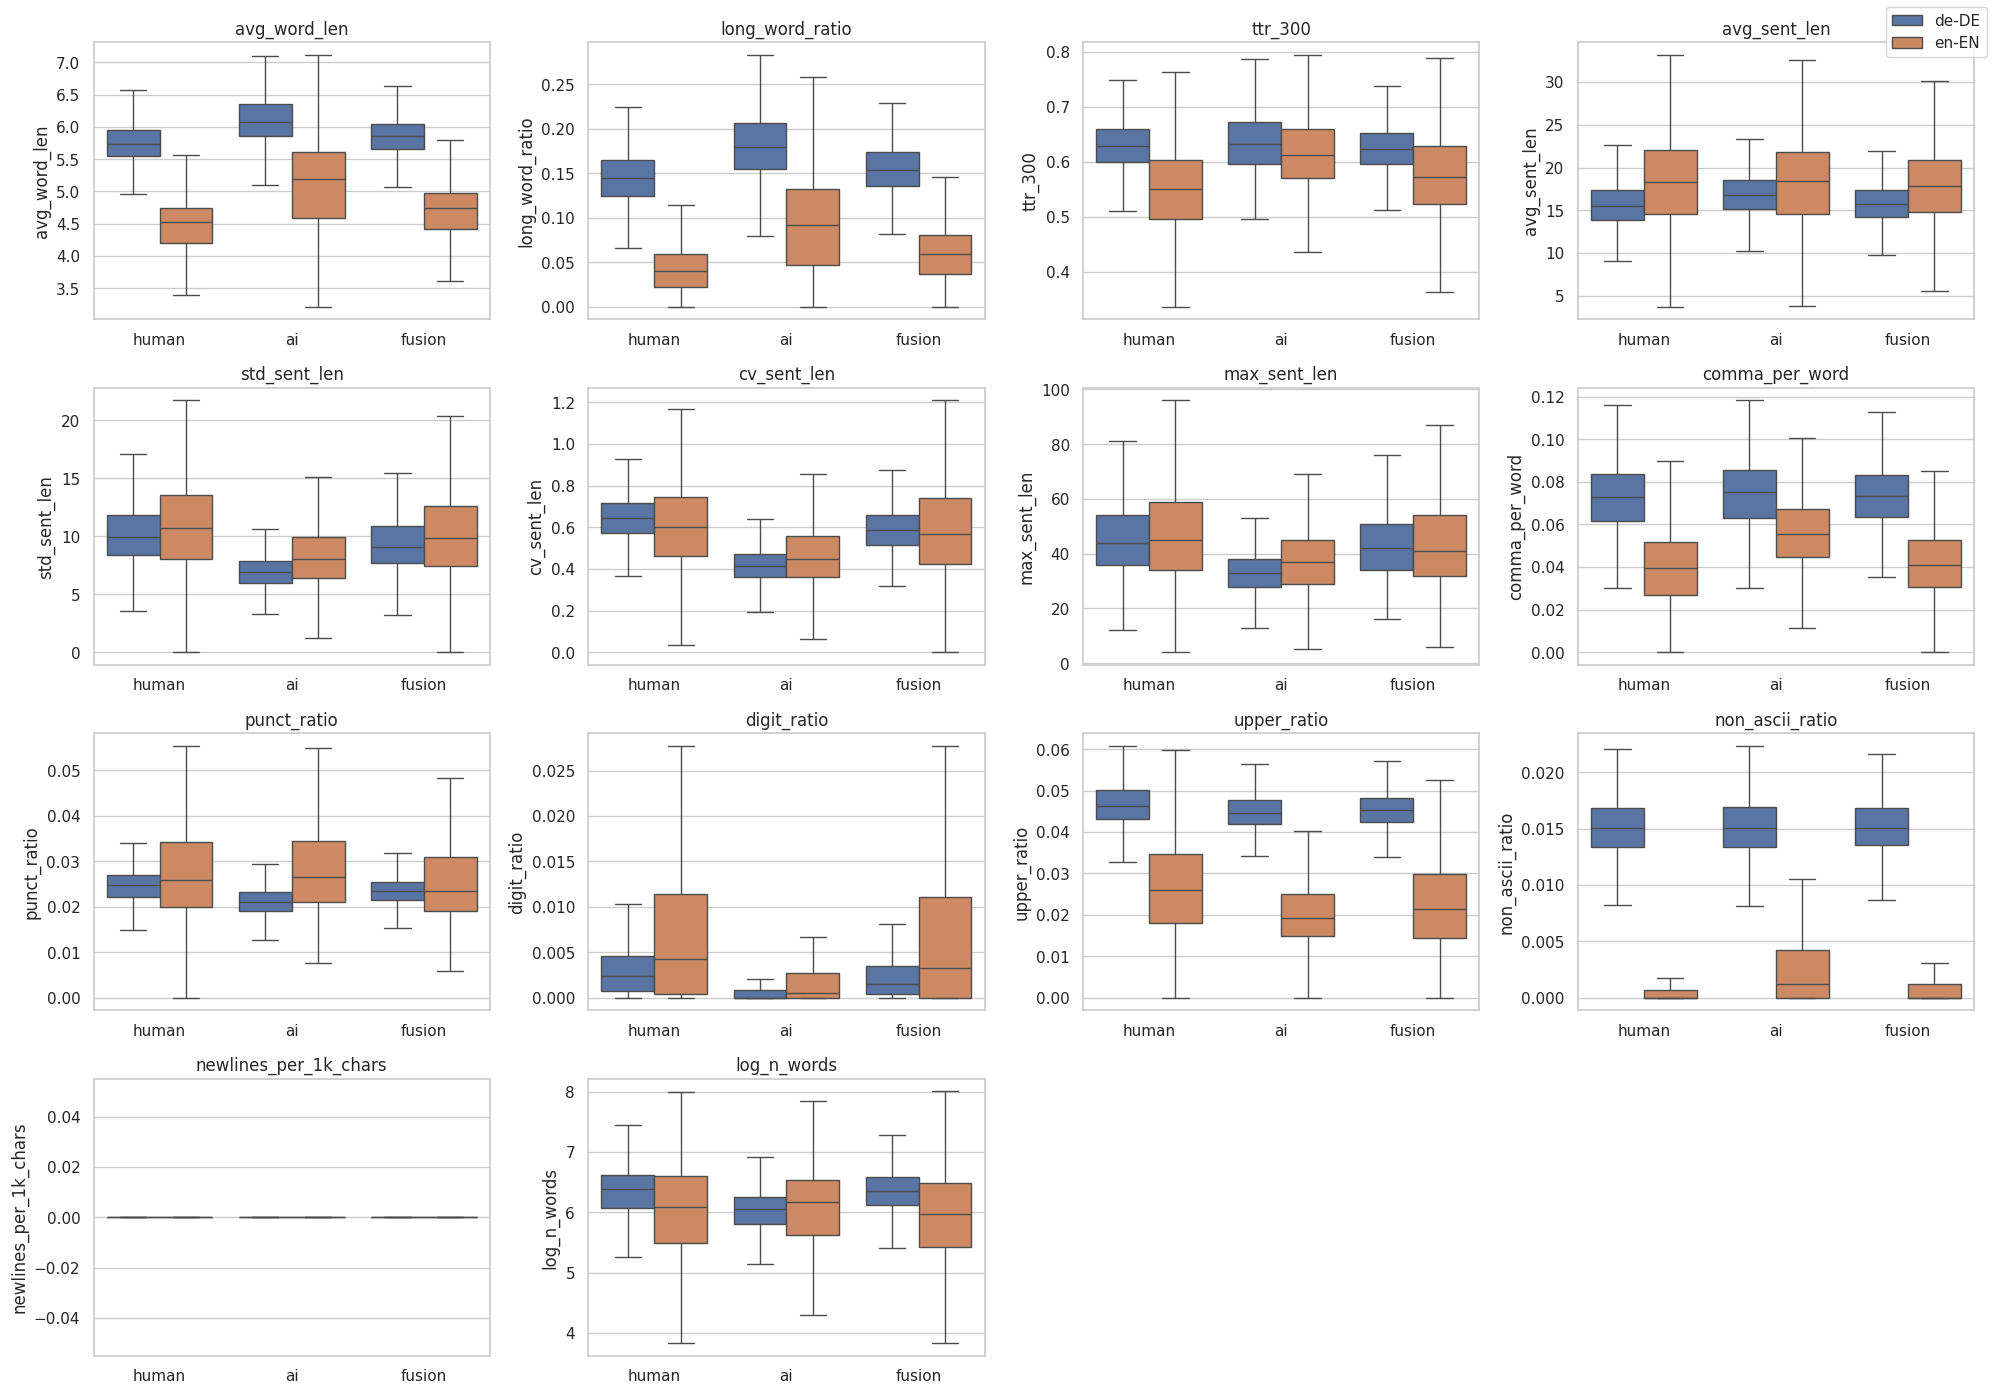

In [22]:
fig, axes = plt.subplots(4, 4, figsize=(20, 14))
for ax, c in zip(axes.ravel(), STYLE_COLS):
    sns.boxplot(data=S, x="label", y=c, hue="lang", order=LABELS, showfliers=False, ax=ax)
    ax.set_title(c); ax.set_xlabel(""); ax.legend_.remove() if ax.get_legend() else None
for ax in axes.ravel()[len(STYLE_COLS):]: ax.axis("off")
handles, labels_ = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels_, loc="upper right"); plt.tight_layout(); plt.show()

In [23]:
def cohens_d(a, b):
    a = pd.to_numeric(pd.Series(a), errors="coerce").dropna().to_numpy(dtype=float)
    b = pd.to_numeric(pd.Series(b), errors="coerce").dropna().to_numpy(dtype=float)
    if len(a) < 2 or len(b) < 2:
        return np.nan
    pooled_var = ((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2)
    if pooled_var <= 1e-24:
        return 0.0 if np.isclose(a.mean(), b.mean()) else np.nan
    return (a.mean() - b.mean()) / np.sqrt(pooled_var)


def safe_kruskal(*samples):
    """Return p=1 by explicit convention for a constant, non-informative feature."""
    arrays = [pd.to_numeric(pd.Series(s), errors="coerce").dropna().to_numpy(dtype=float) for s in samples]
    if any(len(a) == 0 for a in arrays):
        return np.nan
    all_values = np.concatenate(arrays)
    if np.all(all_values == all_values[0]):
        return 1.0
    return stats.kruskal(*arrays).pvalue


rows = []
for lang, sl in S.groupby("lang"):
    for c in STYLE_COLS:
        v = {l: sl.loc[sl.label == l, c] for l in LABELS}
        means = {l: v[l].mean() for l in LABELS}
        gap = means["ai"] - means["human"]
        rows.append({"lang": lang, "feature": c,
                     "d(ai-human)": cohens_d(v["ai"], v["human"]),
                     "d(fusion-human)": cohens_d(v["fusion"], v["human"]),
                     "d(ai-fusion)": cohens_d(v["ai"], v["fusion"]),
                     "kruskal_p": safe_kruskal(*[v[l] for l in LABELS]),
                     "fusion_position": ((means["fusion"] - means["human"]) / gap
                                         if abs(gap) > 1e-12 else np.nan)})
effects = pd.DataFrame(rows).set_index(["lang", "feature"])
display(effects.round(3))
print("fusion_position: 0 = fusion looks like human, 1 = fusion looks like ai; NaN = ai/human means coincide.")
print("For a constant feature across all classes, Kruskal p=1 (no observed separation).")

d(ai-human)  d(fusion-human)  d(ai-fusion)  kruskal_p  fusion_position
lang  feature                                                                                      
de-DE avg_word_len                 0.942            0.300         0.729      0.000            0.262
      long_word_ratio              0.950            0.299         0.741      0.000            0.248
      ttr_300                      0.134           -0.215         0.323      0.000           -1.196
      avg_sent_len                 0.314            0.001         0.362      0.000            0.002
      std_sent_len                -1.367           -0.278        -1.135      0.000            0.238
      cv_sent_len                 -1.998           -0.433        -1.614      0.000            0.229
      max_sent_len                -1.126           -0.090        -0.943      0.000            0.108
      comma_per_word               0.036            0.011         0.028      0.009            0.279
      punct_ratio                 -0.905           -0.295        -0.623      0.000            0.318
      digit_ratio                 -0.918           -0.254        -0.721      0.000            0.325
      upper_ratio                 -0.298           -0.209        -0.113      0.000            0.641
      non_ascii_ratio             -0.042           -0.011        -0.035      0.980            0.226
      newlines_per_1k_chars        0.000            0.000         0.000      1.000              NaN
      log_n_words                 -0.494            0.182        -0.760      0.000           -0.315
en-EN avg_word_len                 1.136            0.501         0.771      0.000            0.323
      long_word_ratio              1.086            0.588         0.714      0.000            0.342
      ttr_300                      0.600            0.200         0.403      0.000            0.347
      avg_sent_len                -0.096           -0.149         0.065      0.000            1.490
      std_sent_len                -0.672           -0.146        -0.558      0.000            0.280
      cv_sent_len                 -0.766           -0.099        -0.640      0.000            0.155
      max_sent_len                -0.590           -0.140        -0.422      0.000            0.312
      comma_per_word               0.797            0.102         0.738      0.000            0.132
      punct_ratio                 -0.016           -0.146         0.155      0.000           10.212
      digit_ratio                 -0.731           -0.070        -0.677      0.000            0.136
      upper_ratio                 -0.372           -0.212        -0.156      0.000            0.624
      non_ascii_ratio              0.171            0.036         0.133      0.000            0.158
      newlines_per_1k_chars        0.000            0.000         0.000      1.000              NaN
      log_n_words                  0.009           -0.024         0.035      0.000           -3.070

fusion_position: 0 = fusion looks like human, 1 = fusion looks like ai; NaN = ai/human means coincide.
For a constant feature across all classes, Kruskal p=1 (no observed separation).


In [24]:
# How well can these features alone separate the classes? (quick sanity check, group-unaware, NOT a baseline)
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import f1_score, confusion_matrix
X = S[STYLE_COLS].assign(lang=(S.lang == "de-DE").astype(int))
y = S.label
pred = cross_val_predict(HistGradientBoostingClassifier(max_iter=150, random_state=SEED), X, y, cv=3)
print("macro-F1 (stylometry only, 3-fold CV):", round(f1_score(y, pred, average="macro"), 4))
display(pd.DataFrame(confusion_matrix(y, pred, labels=LABELS), index=[f"true_{l}" for l in LABELS], columns=[f"pred_{l}" for l in LABELS]))

macro-F1 (stylometry only, 3-fold CV): 0.5622


,pred_human,pred_ai,pred_fusion
true_human,3164,1960,2226
true_ai,237,12416,778
true_fusion,2761,3227,3230


- Stylometric characteristics differ across classes. For example, in English, average word length is **5.13 for AI**, 4.47 for human, and 4.68 for fusion.
- Fusion often exhibits intermediate characteristics between human and AI writing, although this pattern is not consistent across all features.
- A classifier trained only on stylometric features achieved **macro-F1 = 0.5622** in exploratory 3-fold cross-validation.
- Therefore, stylometric features contain useful information but are insufficient as a standalone classification approach. They may be more effective when combined with lexical or contextual representations.

## 9. Character-level and LLM-marker statistics

label,human,ai,fusion,human,ai,fusion
lang,de-DE,de-DE,de-DE,en-EN,en-EN,en-EN
em dash —,0.007,0.000,0.010,0.123,1.322,0.303
en dash –,14.302,4.289,10.923,0.375,2.938,0.560
curly “,2.883,0.806,2.055,0.591,3.022,0.705
curly ”,0.001,0.059,0.005,0.598,2.943,0.702
curly ’,0.076,0.045,0.047,4.229,13.299,3.674
straight ',0.017,0.265,0.037,32.421,18.691,25.908
"straight """,0.004,2.778,0.308,6.993,9.081,6.232
ellipsis …,0.159,0.032,0.684,0.057,0.452,0.086
asterisk *,0.006,0.789,0.098,0.689,2.355,0.424


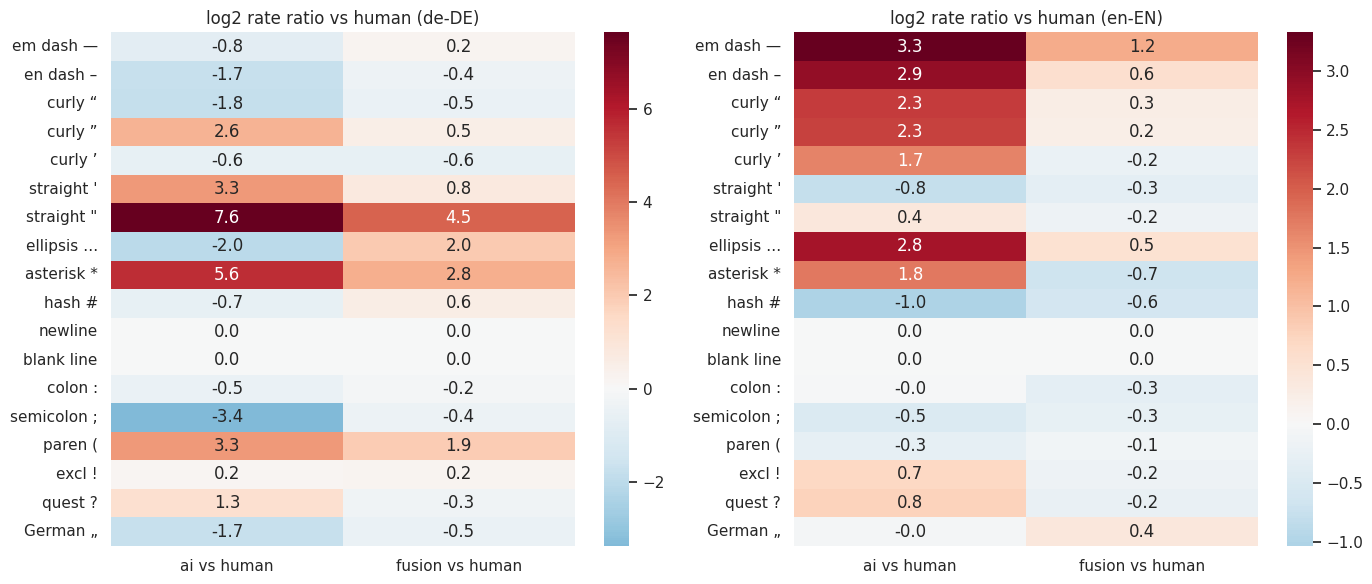

In [25]:
CHARS = {"em dash —": "—", "en dash –": "–", "curly “": "“", "curly ”": "”", "curly ’": "’", "straight '": "'", 'straight "': '"',
         "ellipsis …": "…", "asterisk *": "*", "hash #": "#", "newline": "\n", "blank line": "\n\n", "colon :": ":", "semicolon ;": ";",
         "paren (": "(", "excl !": "!", "quest ?": "?", "German „": "„"}
rate = {}
for name, ch in CHARS.items():
    rate[name] = train_s.text.str.count(re.escape(ch)) / train_s.n_chars.clip(lower=1) * 10_000
R = pd.DataFrame(rate); R[["label", "lang"]] = train_s[["label", "lang"]]
M = R.groupby(["label", "lang"]).mean().T
display(M[[(l, g) for g in sorted(train.lang.unique()) for l in LABELS]])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, lang in zip(axes, sorted(train.lang.unique())):
    lr = np.log2((M[("ai", lang)] + .01) / (M[("human", lang)] + .01)).rename("ai vs human").to_frame()
    lr["fusion vs human"] = np.log2((M[("fusion", lang)] + .01) / (M[("human", lang)] + .01))
    sns.heatmap(lr, annot=True, fmt=".1f", cmap="RdBu_r", center=0, ax=ax); ax.set_title(f"log2 rate ratio vs human ({lang})")
plt.tight_layout(); plt.show()

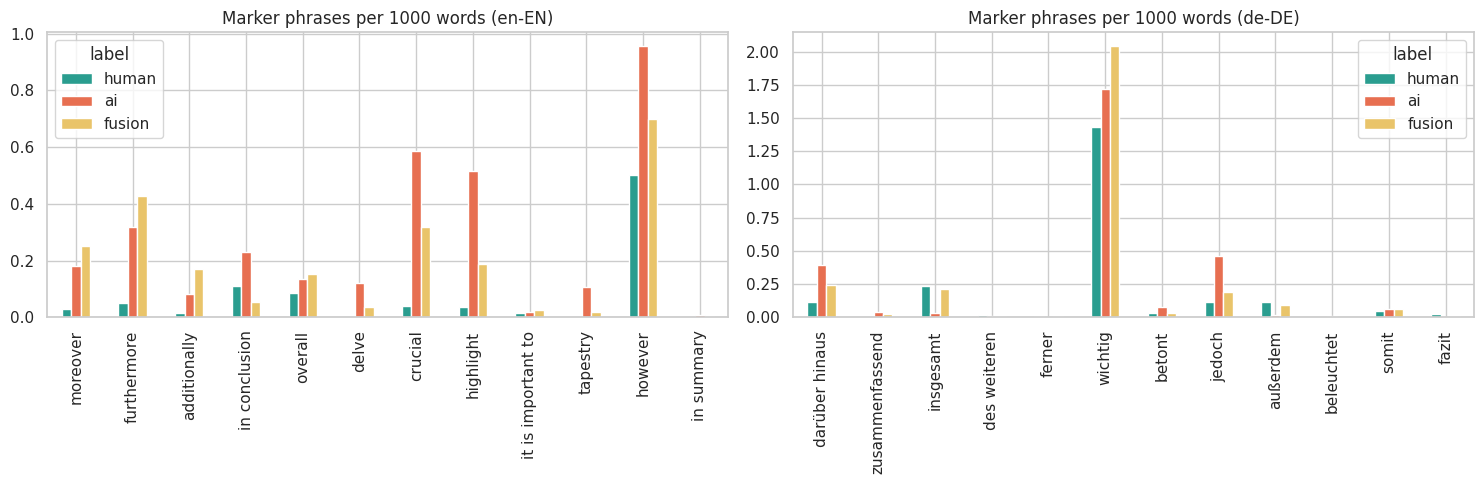

In [26]:
MARKERS = {
  "en-EN": ["moreover", "furthermore", "additionally", "in conclusion", "overall", "delve", "crucial", "highlight", "it is important to", "tapestry", "however", "in summary"],
  "de-DE": ["darüber hinaus", "zusammenfassend", "insgesamt", "des weiteren", "ferner", "wichtig", "betont", "jedoch", "außerdem", "beleuchtet", "somit", "fazit"],
}
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, (lang, words) in zip(axes, MARKERS.items()):
    sl = train_s[train_s.lang == lang]
    low = sl.text.str.lower()
    tab = pd.DataFrame({w: low.str.count(re.escape(w)) / sl.n_words * 1000 for w in words}); tab["label"] = sl.label.values
    tab.groupby("label").mean().reindex(LABELS).T.plot(kind="bar", ax=ax, color=[PALETTE[l] for l in LABELS])
    ax.set_title(f"Marker phrases per 1000 words ({lang})"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

- Punctuation usage differs between classes and languages. In English, em dashes appear more frequently in AI texts, while straight apostrophes are more frequent in human texts.
- German texts show different punctuation patterns, demonstrating that universal punctuation-based rules would be unreliable.
- Certain phrases associated with AI-generated writing may provide useful classification signals. However, their frequency is also influenced by language, domain, and formatting.
- These observations support including character n-grams and lexical features in the baseline model rather than relying on individual marker phrases.

## 10. Lexical differences (log-odds with informative Dirichlet prior)

In [27]:
from sklearn.feature_extraction.text import CountVectorizer

def log_odds(ca, cb, prior):
    a0 = prior.sum()
    na, nb = ca.sum(), cb.sum()
    d = (np.log((ca + prior) / (na + a0 - ca - prior)) - np.log((cb + prior) / (nb + a0 - cb - prior)))
    return d / np.sqrt(1 / (ca + prior) + 1 / (cb + prior))

lex_tables = {}
for lang in sorted(train.lang.unique()):
    sl = train_s[train_s.lang == lang]
    cv = CountVectorizer(lowercase=True, min_df=30, max_features=30_000, token_pattern=r"(?u)\b\w\w+\b")
    X = cv.fit_transform(sl.text)          # EDA only: fitted on a train sample
    vocab = np.array(cv.get_feature_names_out())
    C = {l: np.asarray(X[(sl.label == l).values].sum(0)).ravel().astype(float) for l in LABELS}
    prior = 500 * (sum(C.values()) / sum(C.values()).sum())
    for other in ("ai", "fusion"):
        z = log_odds(C[other], C["human"], prior)
        order = np.argsort(z)
        lex_tables[(lang, other)] = pd.DataFrame({f"more in {other}": vocab[order[::-1][:20]], f"more in human (vs {other})": vocab[order[:20]]})
for k, v in lex_tables.items():
    print(k); display(v)

('de-DE', 'ai')


,more in ai,more in human (vs ai)
0,unsere,das
1,die,ich
2,uns,noch
3,unserer,bei
4,zu,haben
5,sondern,man
6,herausforderungen,aber
7,zukunft,auch
8,lassen,dann
9,müssen,jetzt


('de-DE', 'fusion')


,more in fusion,more in human (vs fusion)
0,müssen,dank
1,herausforderungen,vielen
2,sondern,ich
3,unsere,das
4,nur,herzlichen
5,die,noch
6,gesellschaft,schon
7,sicherstellen,sie
8,unserer,bei
9,lösungen,man


('en-EN', 'ai')


,more in ai,more in human (vs ai)
0,our,had
1,this,applicant
2,these,was
3,within,he
4,we,said
5,legal,have
6,let,the
7,potential,court
8,significant,will
9,learning,on


('en-EN', 'fusion')


,more in fusion,more in human (vs fusion)
0,our,said
1,these,nbsp
2,furthermore,she
3,potential,will
4,this,do
5,model,year
6,crucial,you
7,significant,have
8,challenges,after
9,approach,it


In [28]:
# Most frequent 3-word openings per label
tmp = train_s.copy()
tmp["opening"] = tmp.text.str.lower().str.findall(r"\w+").str[:3].str.join(" ")
for lang, sl in tmp.groupby("lang"):
    print(lang)
    display(pd.concat({l: sl[sl.label == l].opening.value_counts(normalize=True).head(6) for l in LABELS}, axis=1).fillna(0))

de-DE


,human,ai,fusion
opening,,,
sehr geehrte frau,0.197,0.000,0.187
sehr geehrter herr,0.177,0.049,0.157
herr präsident meine,0.090,0.000,0.086
frau präsidentin meine,0.077,0.000,0.076
herr präsident liebe,0.066,0.000,0.071
frau präsidentin liebe,0.059,0.000,0.070
sehr geehrte damen,0.000,0.335,0.000
liebe kolleginnen und,0.000,0.085,0.000
meine damen und,0.000,0.072,0.000


en-EN


,human,ai,fusion
opening,,,
5 the applicant,0.035,0.000,0.044
4 the applicant,0.033,0.000,0.035
if he will,0.021,0.000,0.025
i beg to,0.015,0.000,0.000
dear principal i,0.012,0.011,0.008
by daily mail,0.012,0.000,0.000
mr speaker i,0.000,0.029,0.000
ladies and gentlemen,0.000,0.010,0.000
honourable members i,0.000,0.008,0.000


- Lexical analysis identifies words and expressions associated with different classes. English AI and fusion texts more frequently contain terms such as *potential*, *significant*, *approach*, and *furthermore*.
- Human texts more often contain conversational or source-specific vocabulary.
- Common opening phrases also vary between classes, suggesting that introductory templates can be useful predictive features.
- However, these differences may partly reflect domain characteristics. This motivates evaluating word and character n-gram models alongside multilingual Transformer encoders.

## 11. Train vs. test distribution shift

,KS stat de-DE,KS stat en-EN
feature,,
avg_word_len,0.041,0.022
long_word_ratio,0.030,0.023
ttr_300,0.090,0.066
avg_sent_len,0.041,0.027
std_sent_len,0.049,0.036
cv_sent_len,0.036,0.041
max_sent_len,0.083,0.022
comma_per_word,0.056,0.045
punct_ratio,0.042,0.038


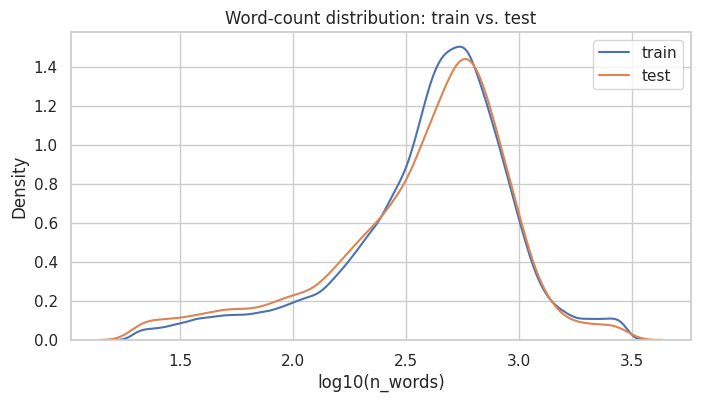

In [29]:
Ts = test.sample(min(10_000, len(test)), random_state=SEED).reset_index(drop=True)
T = pd.DataFrame([style_features(t) for t in Ts.text])
nct = Ts.n_chars.clip(lower=1)
T["punct_ratio"] = Ts.text.str.count(r"[^\w\s]") / nct
T["digit_ratio"] = Ts.text.str.count(r"\d") / nct
T["upper_ratio"] = Ts.text.str.count(r"[A-ZÄÖÜ]") / nct
T["non_ascii_ratio"] = Ts.text.str.count(r"[^\x00-\x7f]") / nct
T["newlines_per_1k_chars"] = Ts.text.str.count("\n") / nct * 1000
T["log_n_words"] = np.log1p(Ts.n_words)
T["lang"] = Ts.lang.values

rows = []
for c in STYLE_COLS:
    r = {"feature": c}
    for lang in sorted(train.lang.unique()):
        ks = stats.ks_2samp(S.loc[S.lang == lang, c], T.loc[T.lang == lang, c])
        r[f"KS stat {lang}"] = ks.statistic
    rows.append(r)
display(pd.DataFrame(rows).set_index("feature"))

fig, ax = plt.subplots(figsize=(8, 4))
sns.kdeplot(np.log10(train.n_words), label="train", ax=ax); sns.kdeplot(np.log10(test.n_words), label="test", ax=ax)
ax.set_xlabel("log10(n_words)"); ax.set_title("Word-count distribution: train vs. test"); ax.legend(); plt.show()

- Train and test differ in language composition, domain proportions, and slightly in document length. The average document length decreases from **542 words in training to 518 in test**.
- Most within-language stylometric differences are relatively modest, suggesting that the datasets are not completely different in writing style.
- Nevertheless, the observed distribution shift may reduce model generalization, especially if a classifier relies heavily on domain-specific or length-related patterns.
- Validation performance should therefore be examined across languages, domains, and document lengths whenever possible.

## 12. Implications for modelling

### Implications for Modelling

The exploratory data analysis leads to several important modelling decisions:

1. **Evaluation metric:** Due to class imbalance, macro-F1 should be the primary evaluation metric, supported by per-class precision, recall, and confusion matrices.

2. **Multilingual classification:** Since the dataset contains English and German texts with different linguistic patterns, multilingual models such as XLM-RoBERTa are appropriate.

3. **Long-document handling:** As approximately 63.5% of sampled texts exceed 512 tokens, simple truncation may discard important information. A head-and-tail strategy is a practical solution worth evaluating.

4. **Feature selection:** Lexical, character-level, and stylometric patterns provide useful classification signals. This supports using TF-IDF with word and character n-grams as a baseline and comparing it with a contextual Transformer model.

5. **Fusion detection:** Fusion texts may preserve substantial human-written content while modifying selected passages. Therefore, identifying local changes and inconsistencies may be more informative than relying only on global document statistics.

6. **Validation reliability:** Differences between train and test distributions, as well as possible relationships between source texts, create risks of biased evaluation. A fixed, reproducible validation split is necessary for fair experiment comparisons, although a group-disjoint split would be preferable if source identifiers were available.

**Overall, the EDA supports comparing complementary lexical and contextual models, evaluating long-text strategies, and focusing on robust discrimination between human and fusion texts.**